In [1]:
import numpy as np
import torch as tc
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from datetime import datetime

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [2]:
path = '/Users/eta/.cache/kagglehub/competitions/spaceship-titanic'
dataset = pd.read_csv(path + '/train.csv')

---

In [3]:
dataset_df = dataset.copy()

In [5]:
# dorp the meanless columns
dataset_df = dataset_df.drop(['PassengerId', 'Cabin', 'Name'], axis=1)

# for Age: replace the nan with the mean value.
dataset_df['Age'] = dataset_df['Age'].fillna(dataset_df['Age'].mean().round())

# for bill: replace the nan with zero value. 
for name in ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']:
    dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna(0)
    
# for category: using the one-hot encoding.
for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP']:
#     print(len(dataset_df[f'{name}'].unique()), dataset_df[f'{name}'].unique())
    dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna('Missing')

In [7]:
# one-hot encoding:
for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP']:
#     print(len(dataset_df[name].unique()), dataset_df[name].unique())
    for key in dataset_df[name].unique():
        dataset_df[f'{name}_{key}'] = 0
        dataset_df.loc[dataset_df[name] == key, f'{name}_{key}'] = 1
        
    dataset_df.drop(columns=[name], inplace=True)

In [9]:
# split the dataset
dataset_x = dataset_df.drop(columns=['Transported'])
dataset_y = dataset_df['Transported']

x_train_df, x_val_df, y_train_df, y_val_df = train_test_split(
    dataset_x,
    dataset_y,
    test_size=0.2,
    random_state=42,
    stratify=dataset_y
)

In [141]:
dataset['PassengerId'].astype

<StringDtype(storage='python', na_value=nan)>

In [4]:
def getData(dataset: pd.DataFrame, istest=False):
    dataset_df = dataset.copy()
    # creat the new feature
    dataset_df['PassengerId'] = [int(i[:4]) for i in dataset_df['PassengerId']]
    dataset_df[["Deck", "Cabin_num", "Side"]] = dataset_df["Cabin"].str.split("/", expand=True)
    dataset_df['Cabin_num'] = dataset_df['Cabin_num'].fillna('0')
    dataset_df['Cabin_num'] = dataset_df['Cabin_num'].astype(int)

    # for Age: replace the nan with the mean value.
    dataset_df['Age'] = dataset_df['Age'].fillna(dataset_df['Age'].mean().round())

    # for bill: replace the nan with zero value. 
    for name in ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']:
        dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna(0)
        
    dataset_df['Cost'] = dataset_df[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].sum(axis=1)

    # for category: using the one-hot encoding.
    for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP', 'Deck', 'Side']:
    #     print(len(dataset_df[f'{name}'].unique()), dataset_df[f'{name}'].unique())
        dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna('Missing')

    # one-hot encoding:
    for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP', 'Deck', 'Side']:
    #     print(len(dataset_df[name].unique()), dataset_df[name].unique())
        for key in dataset_df[name].unique():
            dataset_df[f'{name}_{key}'] = 0
            dataset_df.loc[dataset_df[name] == key, f'{name}_{key}'] = 1

        dataset_df.drop(columns=[name], inplace=True)

    # dorp the meanless columns
    dataset_df = dataset_df.drop(['Cabin', 'Name'], axis=1)

    if istest:
        return dataset_df
    else:
        dataset_x = dataset_df.drop(columns=['Transported'])
        dataset_y = dataset_df['Transported']

        return dataset_x, dataset_y

### Decision tree

In [8]:
dataset_x, dataset_y = getData(dataset)

x_train_df, x_val_df, y_train_df, y_val_df = train_test_split(
    dataset_x,
    dataset_y,
    test_size=0.2,
    random_state=42,
#     stratify=dataset_y
)

In [72]:
def test_result(x_val, forest, alpha_list):
    result = np.zeros(shape=(x_val.shape[0], ))
    for k, k_tree in enumerate(forest):
        predict = np.array(k_tree.predict(x_val), dtype=np.int_) * 2 - 1
        result += alpha_list[k] * predict
    
    return result > 0

In [117]:
N = x_train_df.shape[0]
M = 1000
sample_weight = np.ones(N) / N
alpha_list = []
loss = [np.ones(N)]
exp_loss = []
forest = []

val_acc = []
err_list = []
max_weight = []

for epoch in range(M):

#     print(epoch)
    
    tree = DecisionTreeClassifier(criterion="gini", max_depth=1, random_state=42)
    tree.fit(x_train_df, y_train_df, sample_weight=sample_weight)
    forest.append(tree)
    
    predict = tree.predict(x_train_df)
    wrong = predict != np.array(y_train_df)
    err = np.sum(sample_weight[wrong])
    alpha = (1 / 2) * np.log((1 - err) / err)
    
    L_k = np.exp(-alpha * (np.array(y_train_df, dtype=np.int_) * 2 - 1) * (np.array(predict, dtype=np.int_) * 2 - 1))
    loss.append(L_k * loss[-1])

    sample_weight *= L_k
    sample_weight = sample_weight / np.sum(sample_weight).item()
    
    exp_loss.append(np.sum(loss[-1]) / N)
    err_list.append(err)
    alpha_list.append(alpha)
    max_weight.append([np.argsort(sample_weight)[-1], max(sample_weight)])
    
    if epoch % 50 == 0:
        print(epoch)
        y_val = test_result(x_val_df, forest, alpha_list)
        val_acc.append([epoch, accuracy_score(y_val_df, y_val)])

0
50
100
150
200
250
300
350
400
450
500
550
600
650
700
750
800
850
900
950


Text(0, 0.5, 'max weight index')

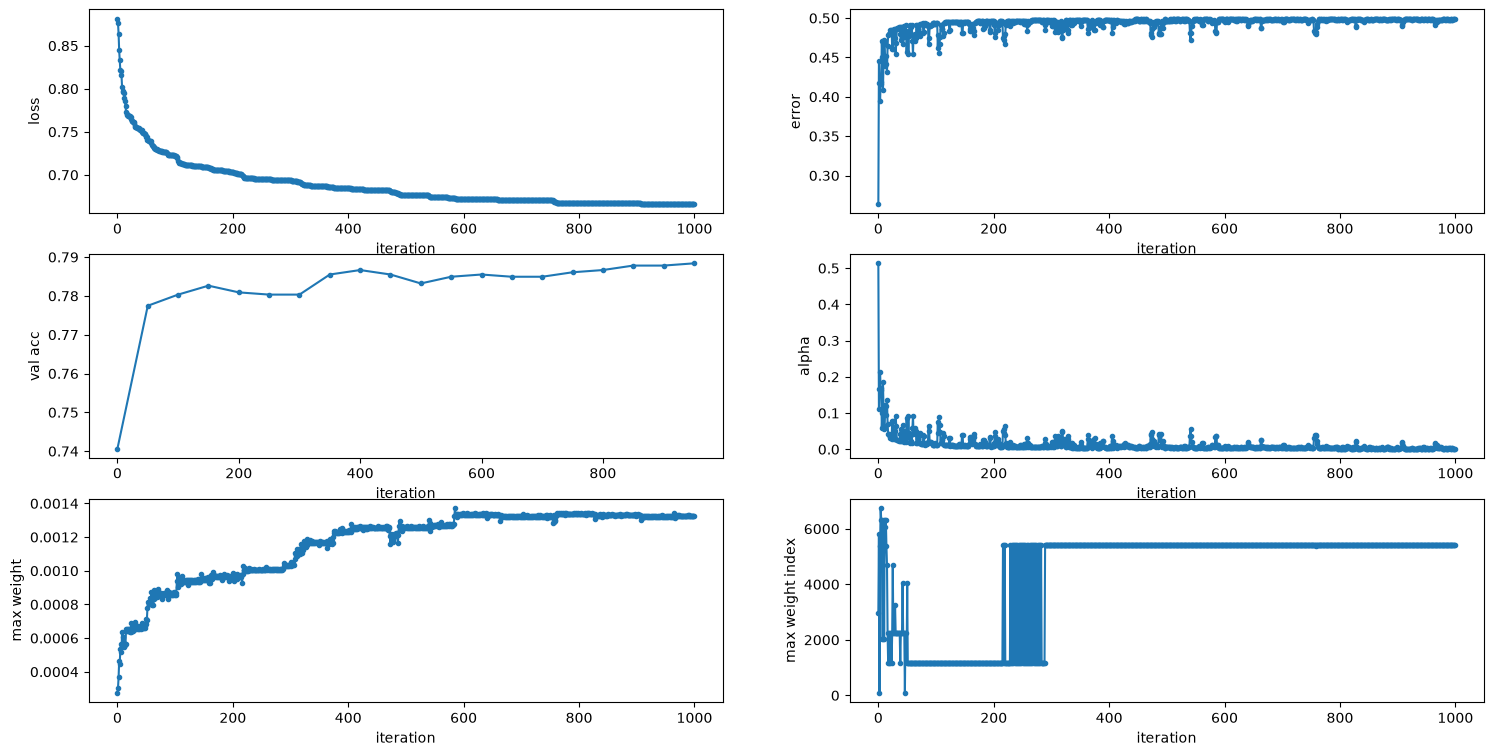

In [121]:
fig, ax = plt.subplots(nrows=3, ncols=2, figsize=(18, 9))

ax[0][0].plot(exp_loss, '.-')
ax[0][0].set_xlabel('iteration')
ax[0][0].set_ylabel('loss')

ax[0][1].plot(err_list, '.-')
ax[0][1].set_xlabel('iteration')
ax[0][1].set_ylabel('error')

ax[1][0].plot(np.array(val_acc)[:, 0], np.array(val_acc)[:, 1], '.-')
ax[1][0].set_xlabel('iteration')
ax[1][0].set_ylabel('val acc')

ax[1][1].plot(alpha_list, '.-')
ax[1][1].set_xlabel('iteration')
ax[1][1].set_ylabel('alpha')

ax[2][0].plot(np.array(max_weight)[:, 1], '.-')
ax[2][0].set_xlabel('iteration')
ax[2][0].set_ylabel('max weight')

ax[2][1].plot(np.array(max_weight)[:, 0], '.-')
ax[2][1].set_xlabel('iteration')
ax[2][1].set_ylabel('max weight index')

In [123]:
np.array(max_weight)[-100:, 0]

array([5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414.])

In [131]:
x_train_df.iloc[5414]

PassengerId                  8007.0
Age                            24.0
RoomService                     0.0
FoodCourt                       0.0
ShoppingMall                   92.0
Spa                          1492.0
VRDeck                          0.0
Cabin_num                     517.0
Cost                         1584.0
HomePlanet_Europa               0.0
HomePlanet_Earth                1.0
HomePlanet_Mars                 0.0
HomePlanet_Missing              0.0
Destination_TRAPPIST-1e         0.0
Destination_PSO J318.5-22       1.0
Destination_55 Cancri e         0.0
Destination_Missing             0.0
CryoSleep_False                 1.0
CryoSleep_True                  0.0
CryoSleep_Missing               0.0
VIP_False                       1.0
VIP_True                        0.0
VIP_Missing                     0.0
Deck_B                          0.0
Deck_F                          0.0
Deck_A                          0.0
Deck_G                          0.0
Deck_Missing                

In [132]:
dataset.iloc[7485]

PassengerId              8007_02
HomePlanet                 Earth
CryoSleep                  False
Cabin                    E/517/P
Destination        PSO J318.5-22
Age                         24.0
VIP                        False
RoomService                  0.0
FoodCourt                    0.0
ShoppingMall                92.0
Spa                       1492.0
VRDeck                       0.0
Name            Marine Gilleyons
Transported                 True
Name: 7485, dtype: object

##### submit

In [134]:
test = pd.read_csv(path + '/test.csv')
sample = pd.read_csv(path + '/sample_submission.csv')

test_df = getData(test, istest=True)
test_df = test_df.reindex(columns=dataset_x.columns, fill_value=0)

In [135]:
test_pred = test_result(test_df, forest, alpha_list)

submit = sample.copy()
submit["Transported"] = test_pred.astype(bool)

In [136]:
submit

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True
...,...,...
4272,9266_02,True
4273,9269_01,False
4274,9271_01,True
4275,9273_01,True


In [137]:
submit.to_csv(f'./data/submit_{datetime.now().isoformat()}.csv', index=False)
submit.to_csv(f'./submit.csv', index=False)

In [138]:
ls

data/                                   titanic_alpha_nueral_network.ipynb
submit.csv                              titanic_alpha_tree_model.ipynb
titanic_alpha_AdaBoost.ipynb            titanic_dataset.ipynb
titanic_alpha_logic_registration.ipynb
